# Learned mosaic training — comparison across runs

Consolidates the per-run `results.ipynb` notebooks that previously lived inside each
`diffusion_retina_learn_results_*` folder. Those notebooks each plotted one run in
isolation on its own colour scale, so comparing settings meant flipping between files
and eyeballing. Here every figure places the runs **side by side on a shared scale**.

Four runs of `diffusion_retina_train.py`, all learning the `ON_Smooth_Monostratified`
mosaic against a frozen four-type encoder:

| run | guidance scale | objective | learning rate | extra regularisers |
|---|---|---|---|---|
| `eta013`   | 0.013   | random timesteps (`n_gradient_steps=10`) | 1e-4 | none |
| `eta035`   | 0.035   | final-stage (`differentiable_steps=1`)   | 1e-4 | none |
| `eta09402` | 0.09402 | final-stage (`differentiable_steps=1`)   | 1e-4 | none |
| `perstep`  | 0.035   | per-step MAP (`train_mode=per_step_map`) | 2e-5 | smoothness, rate budget, diversity |

**These runs are not a clean factorial design — read the comparisons accordingly.**
Section 1 derives the differences from the saved configs rather than from this table,
so it stays correct if the data changes.

* **`eta035` vs `eta09402` is the only controlled contrast.** Identical objective,
  learning rate and regularisation; guidance scale alone differs (0.035 vs 0.094).
* **`eta013` changes the objective as well as the scale**, so a difference between it
  and the other two cannot be attributed to guidance strength.
* **`perstep` differs from `eta035` on 13 config keys**, including a 5× lower
  learning rate and three regularisation terms that are off everywhere else. Treat it
  as a separate experiment, not as an objective ablation.

Data lives in `results/retina_learn/<run>/` (outside the repository, as experiment
output should).

In [1]:
from pathlib import Path
import json

import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Walk up to the project root so the notebook runs from anywhere.
ROOT = Path.cwd()
while not (ROOT / "results").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RUN_DIR = ROOT / "results" / "retina_learn"

# Fixed run order; the colour assigned to a run never changes between figures, so a
# line keeps its identity across the notebook.
RUNS = ["eta013", "eta035", "eta09402", "perstep"]
LABELS = {"eta013": "eta=0.013", "eta035": "eta=0.035",
          "eta09402": "eta=0.094", "perstep": "per-step (eta=0.035)"}

# Categorical slots 1, 2, 3, 7. Slot 4 (yellow) was rejected: against slot 2 it
# scores dE=13.7 in normal vision, under the floor of 15. Violet scores 16.3 with a
# worst-case colour-vision-deficient separation of 10.0.
COLORS = {"eta013": "#2a78d6", "eta035": "#eb6834",
          "eta09402": "#1baf7a", "perstep": "#4a3aa7"}

INK, INK_2, GRID = "#0b0b0b", "#52514e", "#dcdbd6"
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.6,
    "legend.frameon": False,
})

# Subunit kernels are signed and roughly zero-mean, so magnitude alone would hide
# the centre/surround structure. A diverging map with a neutral midpoint and
# symmetric limits puts zero at the neutral colour and makes sign readable.
SIGNED = LinearSegmentedColormap.from_list(
    "signed", ["#104281", "#2a78d6", "#f0efec", "#e34948", "#8c1d1c"]
)

configs = {}
for run in RUNS:
    with open(RUN_DIR / run / "config.json") as handle:
        configs[run] = json.load(handle)

weights = {run: h5py.File(RUN_DIR / run / "learned_mosaic_weights.h5", "r") for run in RUNS}
epochs_per_run = {run: sorted(int(k.split("_")[1]) for k in f) for run, f in weights.items()}
COMMON_EPOCHS = sorted(set.intersection(*(set(e) for e in epochs_per_run.values())))

for run in RUNS:
    e = epochs_per_run[run]
    print(f"{run:10s} {len(e):3d} checkpoints, epochs {min(e)}-{max(e)} step {e[1] - e[0]}")
print(f"\ncommon epochs used for matched comparisons: {COMMON_EPOCHS}")

import pandas as pd

def summed_kernel(run, epoch):
    """Summed subunit kernel for one run at one epoch, as a 2-D array."""
    return np.asarray(weights[run][f"epoch_{epoch:04d}"]["summed_subunit_kernel"]).squeeze()

eta013      50 checkpoints, epochs 2-100 step 2
eta035      50 checkpoints, epochs 2-100 step 2
eta09402    50 checkpoints, epochs 2-100 step 2
perstep     20 checkpoints, epochs 5-100 step 5

common epochs used for matched comparisons: [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]


## 1. What actually differs between the runs

Only the keys that vary are shown; everything else was held fixed.

In [2]:
import pandas as pd

table = pd.DataFrame(configs).T.reindex(RUNS)

# repr(), not astype(str): pandas preserves missing values through astype(str), and
# nunique() then drops them, so a key that is None in two runs and set in the other
# two looks constant. That silently hid the objective difference
# (differentiable_steps / n_gradient_steps), which is the whole point of the table.
PATHS = {"output_dir", "config", "diffusion_params", "device"}
varying = [c for c in table.columns
           if c not in PATHS and table[c].map(repr).nunique() > 1]
display(table[varying].rename(index=LABELS).fillna("-"))
print("held constant:", ", ".join(sorted(set(table.columns) - set(varying) - PATHS)))

,num_workers,learning_rate,differentiable_steps,guidance_scale,rf_smoothness_weight,rate_budget_weight,diversity_weight,output_every_epochs,weight_save_every_epochs,n_gradient_steps,train_mode,map_update_every,step_loss_weighting,learned_weight,kernel_parameterization,learned_subunit_nonlinearity,learned_output_nonlinearity,learned_rf_scale
eta=0.013,4,0.0001,-,0.013,0,0,0,20,2,10,-,-,-,-,-,-,-,-
eta=0.035,8,0.0001,1,0.035,0,0,0,20,2,-,-,-,-,-,-,-,-,-
eta=0.094,4,0.0001,1,0.09402,0,0,0,20,2,-,-,-,-,-,-,-,-,-
per-step (eta=0.035),4,0.00002,-,0.035,0.001,0.000001,0.001,5,5,10,per_step_map,1,alpha_prev,1.0,zero_mean_unit_norm,-,-,1.0


held constant: batch_size, epochs, force_math_sdp, grad_clip_norm, guidance_normalization, image_size, include_cell_types, learn_cell_type, learned_init_seed, learned_n_cells, mixed_precision, model_id, num_inference_steps, params, rate_noise_std, seed, target_image, weight_decay


## 2. Did these runs actually learn anything?

Ask this before reading any kernel image. Two measurements:

* **movement** — how far the summed kernel travelled between the first and last
  common epoch, relative to its starting norm.
* **similarity** — the correlation between the final kernels of each pair of runs.

If a run's kernel barely moved, its images show the initialisation, not a learned
receptive field, and any apparent effect of guidance scale is noise.

,"relative movement, epoch 10->100",final |kernel| max,kernel parameterisation
run,,,
eta=0.013,3.58e-05,6.011e-04,(none)
eta=0.035,1.81e-05,6.011e-04,(none)
eta=0.094,4.92e-05,6.012e-04,(none)
per-step (eta=0.035),8.88e-01,9.873e-02,zero_mean_unit_norm


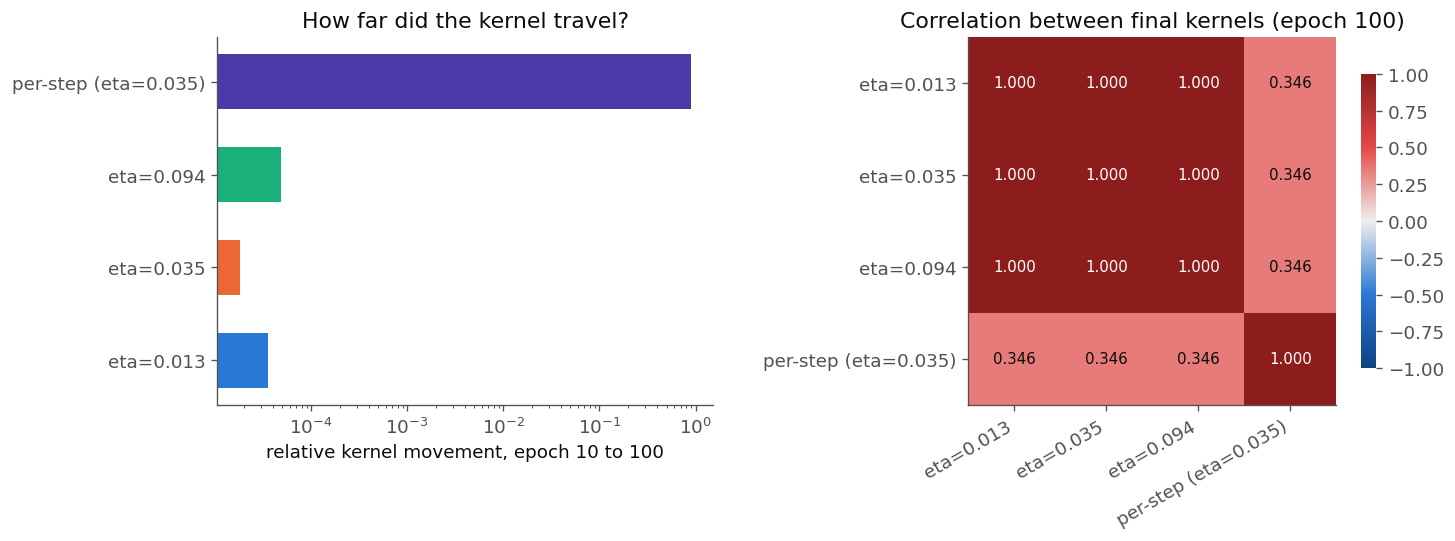

In [3]:
first, last = COMMON_EPOCHS[0], COMMON_EPOCHS[-1]
finals = {r: summed_kernel(r, last) for r in RUNS}

rows = []
for run in RUNS:
    start = summed_kernel(run, first)
    rows.append({
        "run": LABELS[run],
        f"relative movement, epoch {first}->{last}": np.linalg.norm(finals[run] - start) / np.linalg.norm(start),
        "final |kernel| max": np.abs(finals[run]).max(),
        "kernel parameterisation": configs[run].get("kernel_parameterization") or "(none)",
    })
movement = pd.DataFrame(rows).set_index("run")
display(movement.style.format({
    f"relative movement, epoch {first}->{last}": "{:.2e}",
    "final |kernel| max": "{:.3e}"}))

sim = np.array([[np.corrcoef(finals[a].ravel(), finals[b].ravel())[0, 1] for b in RUNS] for a in RUNS])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
axes[0].barh([LABELS[r] for r in RUNS],
             [movement.iloc[i, 0] for i in range(len(RUNS))],
             color=[COLORS[r] for r in RUNS], height=0.6)
axes[0].set(xscale="log", xlabel=f"relative kernel movement, epoch {first} to {last}",
            title="How far did the kernel travel?")
axes[0].grid(axis="y", visible=False)
axes[0].set_axisbelow(True)

im = axes[1].imshow(sim, cmap=SIGNED, vmin=-1, vmax=1)
axes[1].set(xticks=range(len(RUNS)), yticks=range(len(RUNS)),
            title=f"Correlation between final kernels (epoch {last})")
axes[1].set_xticklabels([LABELS[r] for r in RUNS], rotation=30, ha="right")
axes[1].set_yticklabels([LABELS[r] for r in RUNS])
axes[1].grid(False)
for i in range(len(RUNS)):
    for j in range(len(RUNS)):
        axes[1].text(j, i, f"{sim[i, j]:.3f}", ha="center", va="center", fontsize=9,
                     color="white" if abs(sim[i, j]) > 0.6 else INK)
bar = fig.colorbar(im, ax=axes[1], shrink=0.8)
bar.outline.set_visible(False)
plt.show()

## 3. Summed subunit kernel over training

Each panel shows the kernel **minus its own mean**, on a symmetric scale set per row.
Two corrections are needed to make these panels say anything:

* The non-learning runs produce a near-constant *positive* field (mean ~6e-4, standard
  deviation ~1e-5). On a symmetric scale around zero, every pixel saturates at one end
  and the panel is a solid block. Removing the panel mean exposes the residual shape.
* A single shared scale across rows is also wrong: `perstep` uses `zero_mean_unit_norm`
  parameterisation and its weights are ~160x larger by construction, which flattens
  every other row. Each row therefore carries its own limit, printed at the left.

These panels show **shape only**. Magnitude lives in section 2.

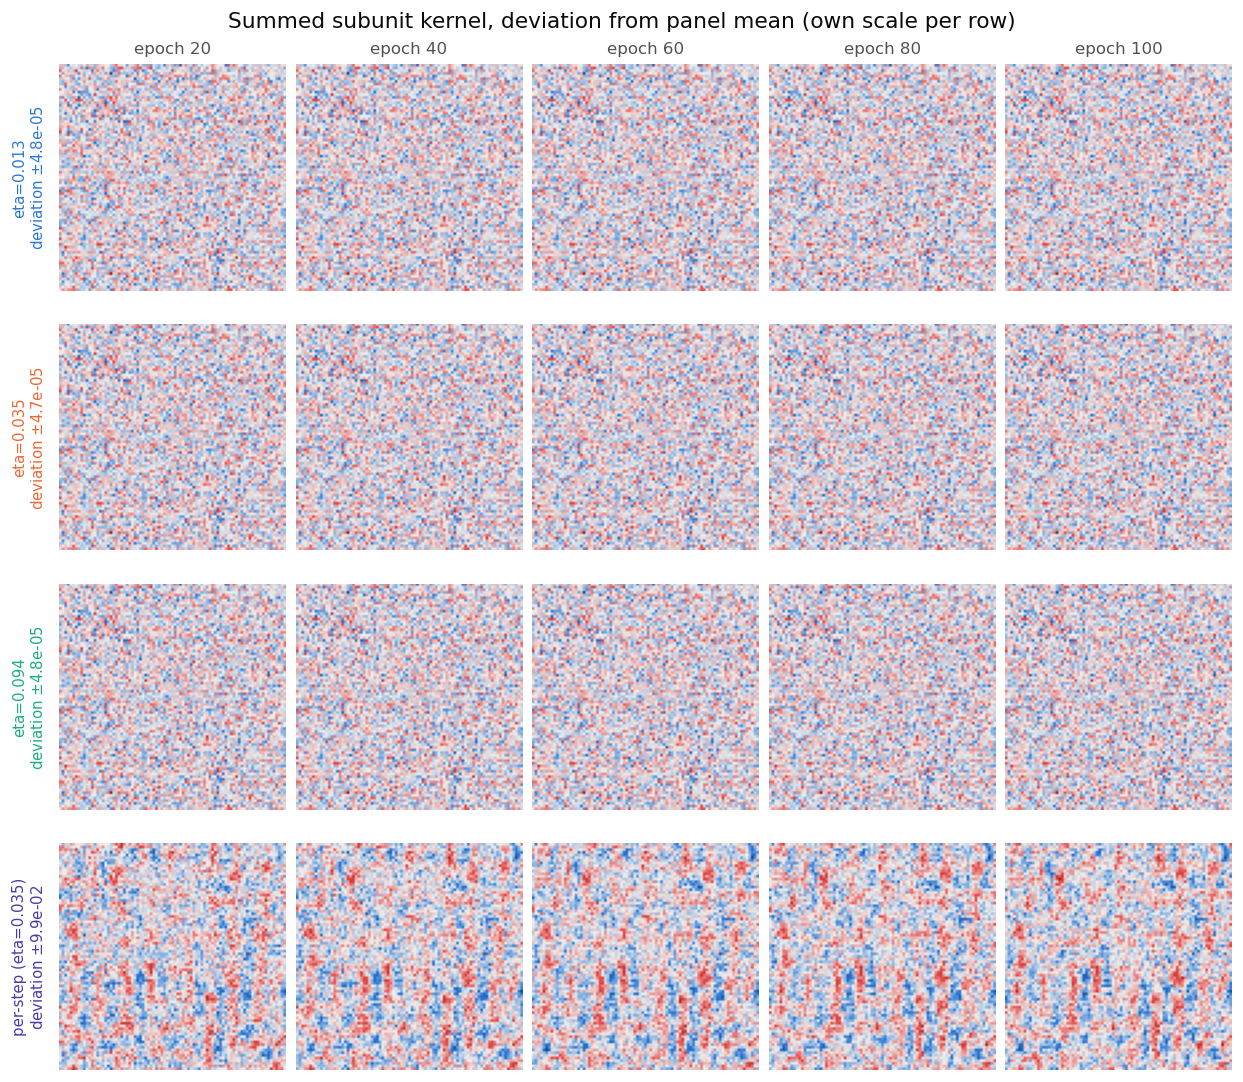

In [4]:
show_epochs = COMMON_EPOCHS[1::2]          # every 20th epoch, 20..100
panels = {(r, e): summed_kernel(r, e) for r in RUNS for e in show_epochs}
# Remove each panel's DC level; a near-constant field otherwise saturates the map.
dev = {k: v - v.mean() for k, v in panels.items()}

fig, axes = plt.subplots(len(RUNS), len(show_epochs),
                         figsize=(2.05 * len(show_epochs), 2.25 * len(RUNS)),
                         constrained_layout=True)
for i, run in enumerate(RUNS):
    row_limit = max(np.abs(dev[(run, e)]).max() for e in show_epochs)
    for j, epoch in enumerate(show_epochs):
        ax = axes[i, j]
        ax.imshow(dev[(run, epoch)], cmap=SIGNED, vmin=-row_limit, vmax=row_limit)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        if i == 0:
            ax.set_title(f"epoch {epoch}", fontsize=10, color=INK_2)
    axes[i, 0].set_ylabel(f"{LABELS[run]}\ndeviation $\\pm${row_limit:.1e}",
                          fontsize=9, color=COLORS[run], labelpad=8)

fig.suptitle("Summed subunit kernel, deviation from panel mean (own scale per row)", fontsize=13)
plt.show()

## 4. The four functional subunits at the final epoch

Again one scale per row, for the same reason.

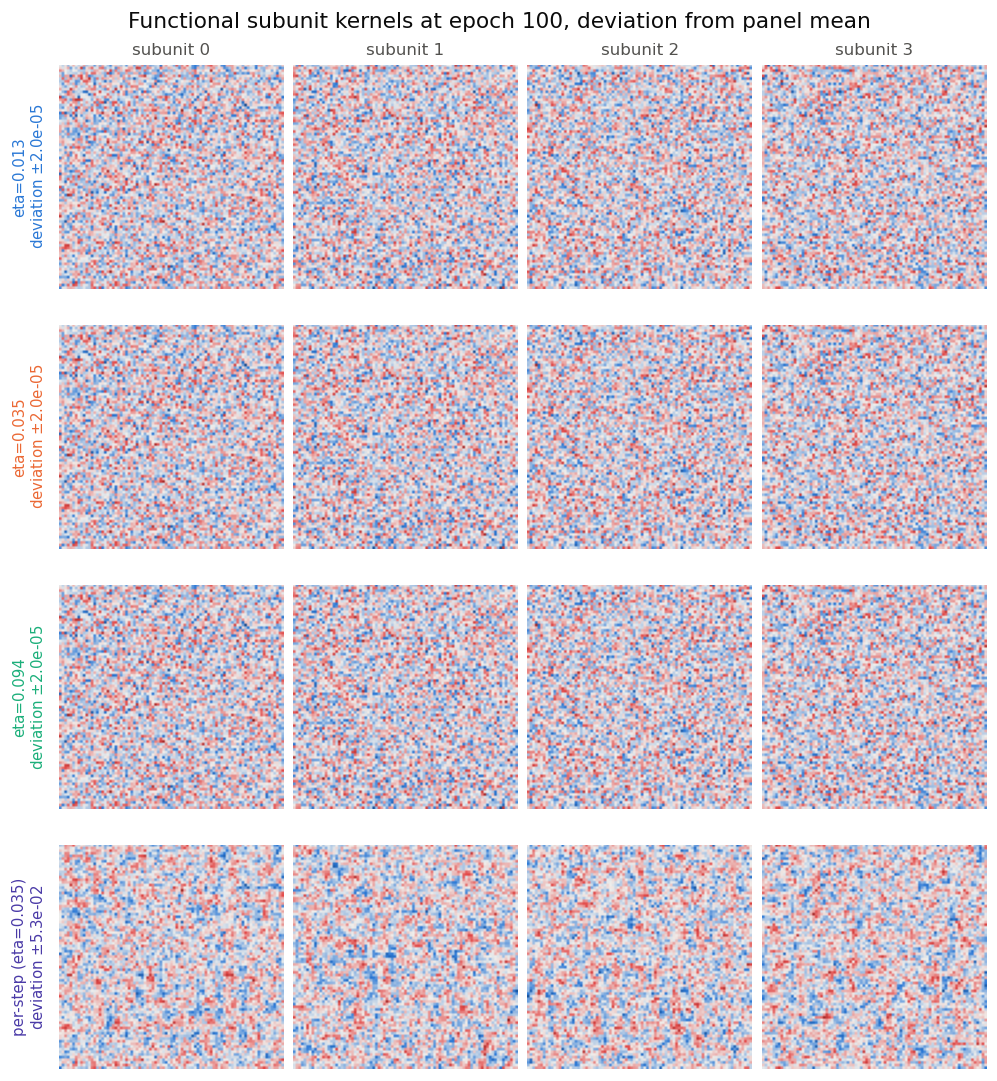

In [5]:
FINAL = COMMON_EPOCHS[-1]

def functional(run, epoch):
    return np.asarray(weights[run][f"epoch_{epoch:04d}"]["functional_subunit_kernels"]).squeeze()

funcs = {r: functional(r, FINAL) for r in RUNS}
n_sub = funcs[RUNS[0]].shape[0]

fig, axes = plt.subplots(len(RUNS), n_sub, figsize=(2.05 * n_sub, 2.25 * len(RUNS)),
                         constrained_layout=True)
for i, run in enumerate(RUNS):
    dev_k = funcs[run] - funcs[run].mean(axis=(1, 2), keepdims=True)
    row_limit = np.abs(dev_k).max()
    for j in range(n_sub):
        ax = axes[i, j]
        ax.imshow(dev_k[j], cmap=SIGNED, vmin=-row_limit, vmax=row_limit)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        if i == 0:
            ax.set_title(f"subunit {j}", fontsize=10, color=INK_2)
    axes[i, 0].set_ylabel(f"{LABELS[run]}\ndeviation $\\pm${row_limit:.1e}",
                          fontsize=9, color=COLORS[run], labelpad=8)

fig.suptitle(f"Functional subunit kernels at epoch {FINAL}, deviation from panel mean", fontsize=13)
plt.show()

## 5. Has training converged?

Images alone cannot answer this. Two scalar traces per run, on their own axes (never
a second y-scale on one plot):

* **left** — the relative change in the summed kernel between consecutive saved
  checkpoints. Falling toward zero means the kernel has stopped moving.
* **right** — how differentiated the four subunits are, measured as the mean pairwise
  correlation between them. A value near 1 means the subunits collapsed onto each
  other and the extra capacity bought nothing.

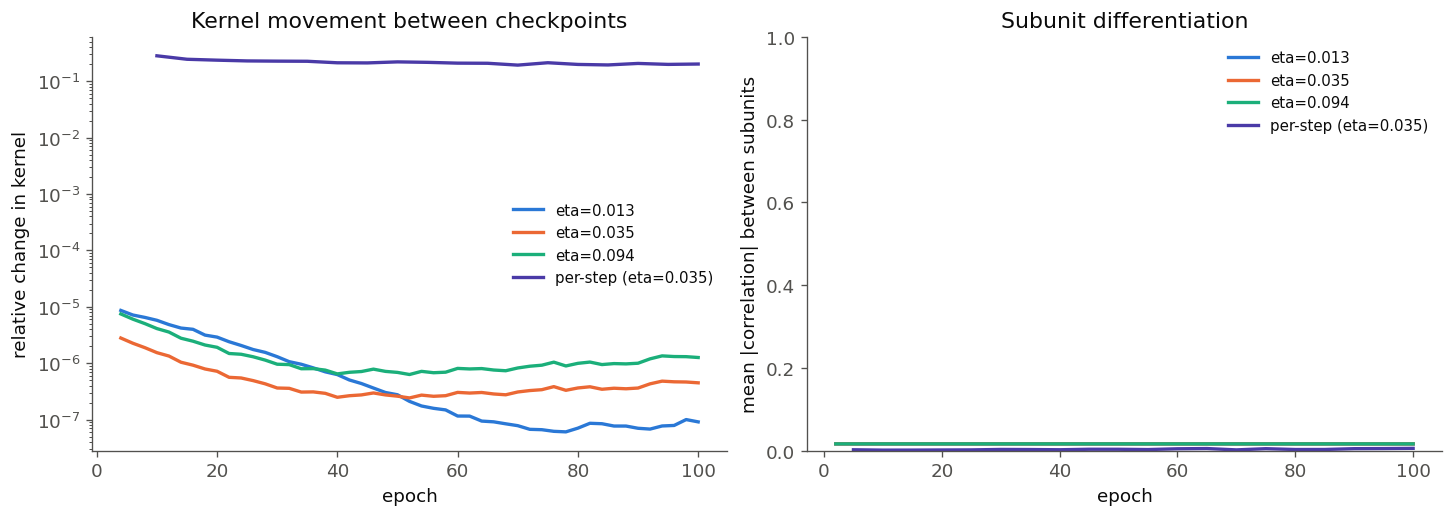

In [6]:
def kernel_series(run):
    eps = epochs_per_run[run]
    return eps, np.stack([summed_kernel(run, e) for e in eps])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

for run in RUNS:
    eps, stack = kernel_series(run)
    step = np.linalg.norm(np.diff(stack, axis=0).reshape(len(eps) - 1, -1), axis=1)
    step /= np.linalg.norm(stack[:-1].reshape(len(eps) - 1, -1), axis=1)
    axes[0].plot(eps[1:], step, color=COLORS[run], lw=2, label=LABELS[run])

    corr = []
    for e in eps:
        k = functional(run, e).reshape(n_sub, -1)
        k = (k - k.mean(axis=1, keepdims=True)) / (k.std(axis=1, keepdims=True) + 1e-12)
        c = (k @ k.T) / k.shape[1]
        corr.append(np.abs(c[np.triu_indices(n_sub, 1)]).mean())
    axes[1].plot(eps, corr, color=COLORS[run], lw=2, label=LABELS[run])

axes[0].set(xlabel="epoch", ylabel="relative change in kernel", yscale="log",
            title="Kernel movement between checkpoints")
axes[1].set(xlabel="epoch", ylabel="mean |correlation| between subunits", ylim=(0, 1),
            title="Subunit differentiation")
for ax in axes:
    ax.legend(fontsize=9)
    ax.set_axisbelow(True)
plt.show()

## 6. Learned nonlinearity parameters

One panel per learned scalar, one line per run, shared x-axis. These are the subunit
and output nonlinearity parameters the training actually adjusts.

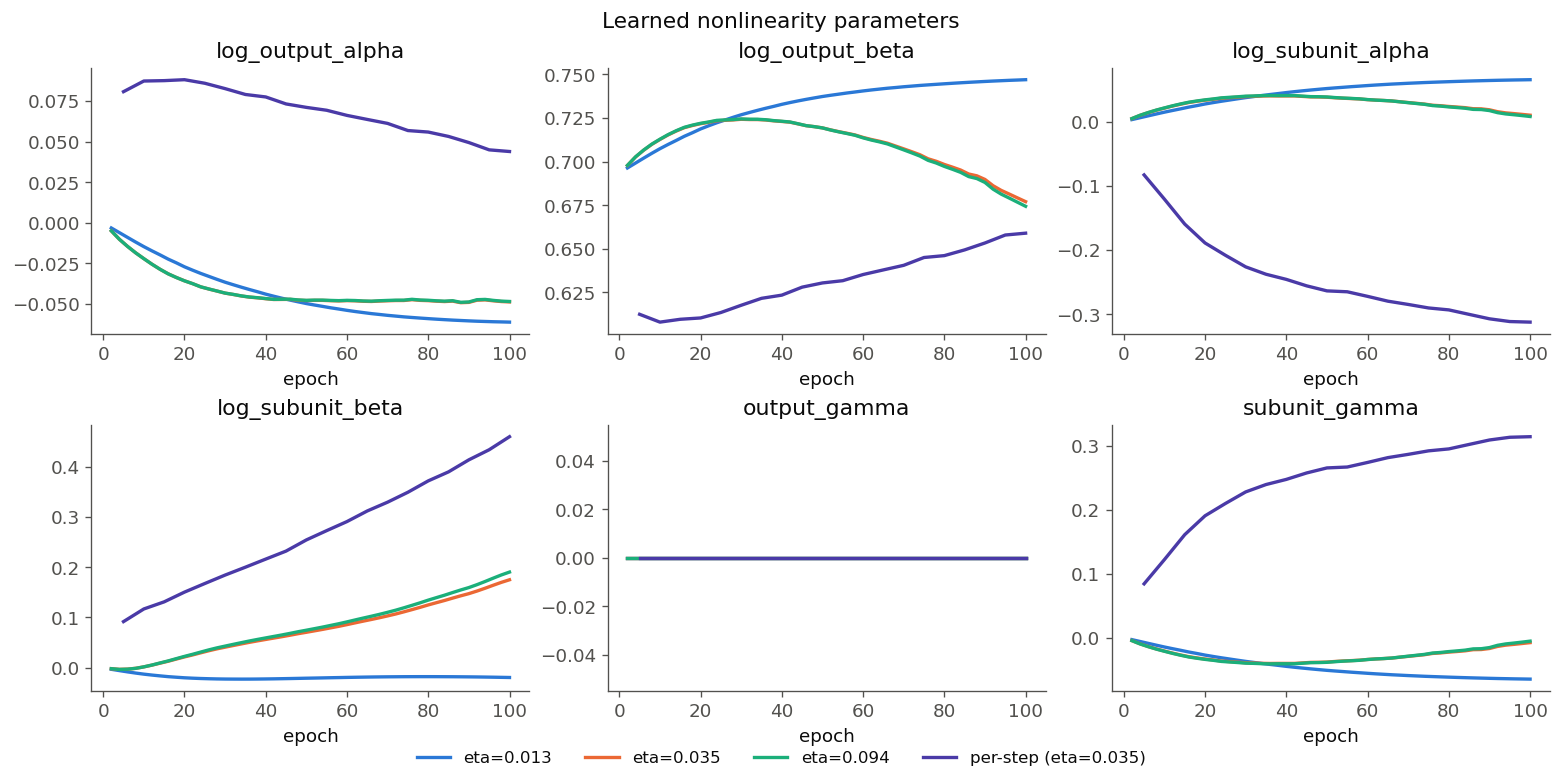

In [7]:
keys = [k for k in weights[RUNS[0]][f"epoch_{COMMON_EPOCHS[0]:04d}"]
        if weights[RUNS[0]][f"epoch_{COMMON_EPOCHS[0]:04d}"][k].shape == ()]

ncol = 3
nrow = int(np.ceil(len(keys) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.3 * ncol, 3.1 * nrow), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, key in zip(axes, keys):
    for run in RUNS:
        eps = epochs_per_run[run]
        vals = [float(np.asarray(weights[run][f"epoch_{e:04d}"][key])) for e in eps]
        ax.plot(eps, vals, color=COLORS[run], lw=2, label=LABELS[run])
    ax.set(xlabel="epoch", title=key)
    ax.set_axisbelow(True)
for ax in axes[len(keys):]:
    ax.set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(RUNS), fontsize=10,
           bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Learned nonlinearity parameters", fontsize=13)
plt.show()

## 7. Mosaic geometry

Cell centres are initialised from the hexagonal lattice and may drift during training.
Overlaying the runs shows whether guidance strength moved the mosaic itself or only
the kernels.

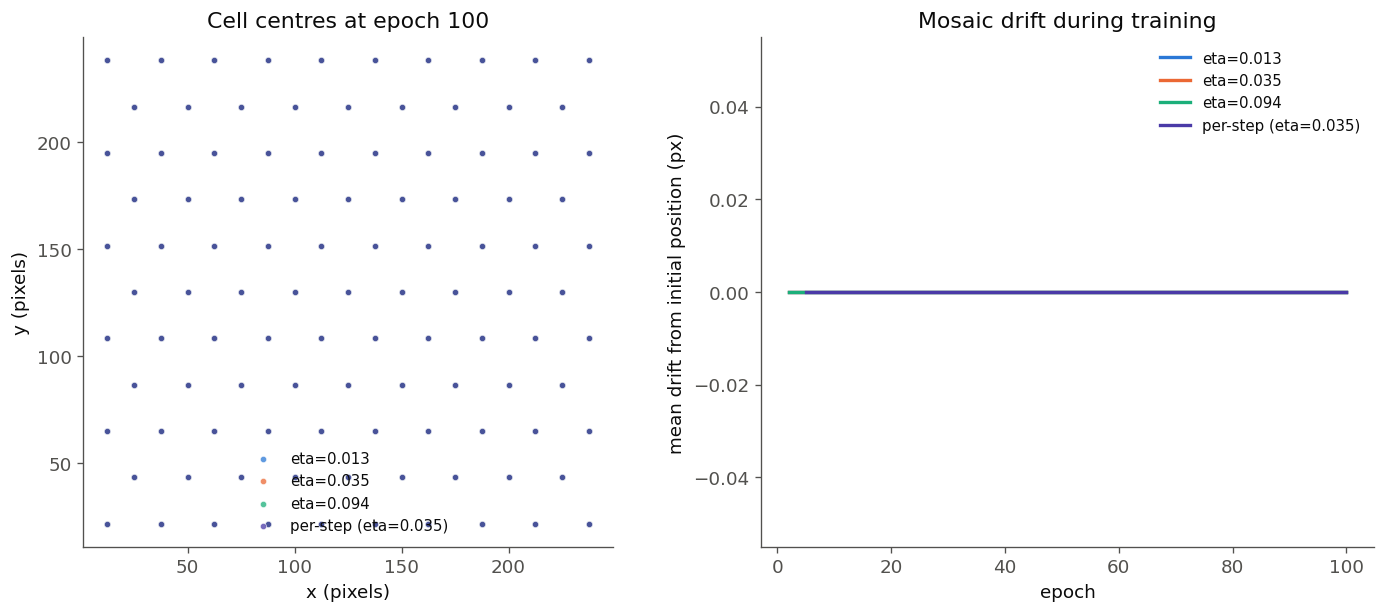

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), constrained_layout=True)

for run in RUNS:
    start = np.asarray(weights[run][f"epoch_{epochs_per_run[run][0]:04d}"]["cell_centres"])
    end = np.asarray(weights[run][f"epoch_{FINAL:04d}"]["cell_centres"])
    axes[0].scatter(end[:, 0], end[:, 1], s=14, color=COLORS[run], alpha=0.75,
                    edgecolor="white", linewidth=0.4, label=LABELS[run])
    axes[1].plot(epochs_per_run[run],
                 [np.linalg.norm(np.asarray(weights[run][f"epoch_{e:04d}"]["cell_centres"]) - start, axis=1).mean()
                  for e in epochs_per_run[run]],
                 color=COLORS[run], lw=2, label=LABELS[run])

axes[0].set(xlabel="x (pixels)", ylabel="y (pixels)", title=f"Cell centres at epoch {FINAL}")
axes[0].set_aspect("equal")
axes[1].set(xlabel="epoch", ylabel="mean drift from initial position (px)",
            title="Mosaic drift during training")
for ax in axes:
    ax.legend(fontsize=9)
    ax.set_axisbelow(True)
plt.show()

## What this consolidation shows

**Only `perstep` trained.** Its summed kernel moves by ~0.9 relative between epochs 10
and 100. The three others move by 2-5e-5 — four orders of magnitude less — and their
final kernels correlate with each other at r > 0.99999. They converged to the same
thing regardless of guidance scale because they effectively did not move from
initialisation.

The practical consequence: **`eta013` / `eta035` / `eta09402` cannot be used to say
anything about guidance scale.** The apparent "effect" of eta in those three runs is
the absence of learning, not a response to the parameter. That is visible here and was
not visible in the separate per-run notebooks, each of which normalised its own
images and so made a flat kernel look like structure.

Caveats on the design, derived from the configs in section 1:

* `eta035` vs `eta09402` would have been the only controlled contrast (guidance scale
  alone), but both are in the non-learning group.
* `eta013` co-varies the objective; `perstep` co-varies 13 keys including a 5x lower
  learning rate, three regularisers and `zero_mean_unit_norm` kernel parameterisation.
  `perstep` is therefore a separate experiment, not an ablation of the others.
* Kernel panels are normalised per row. Absolute magnitudes are not comparable across
  parameterisations and are reported in section 2 instead.
* The un-suffixed `diffusion_retina_learn_results/` folder held a notebook but no
  `learned_mosaic_weights.h5`, so it contributed no data.

Close the open HDF5 handles when finished.

In [9]:
for handle in weights.values():
    handle.close()
print("closed", len(weights), "HDF5 files")

closed 4 HDF5 files
